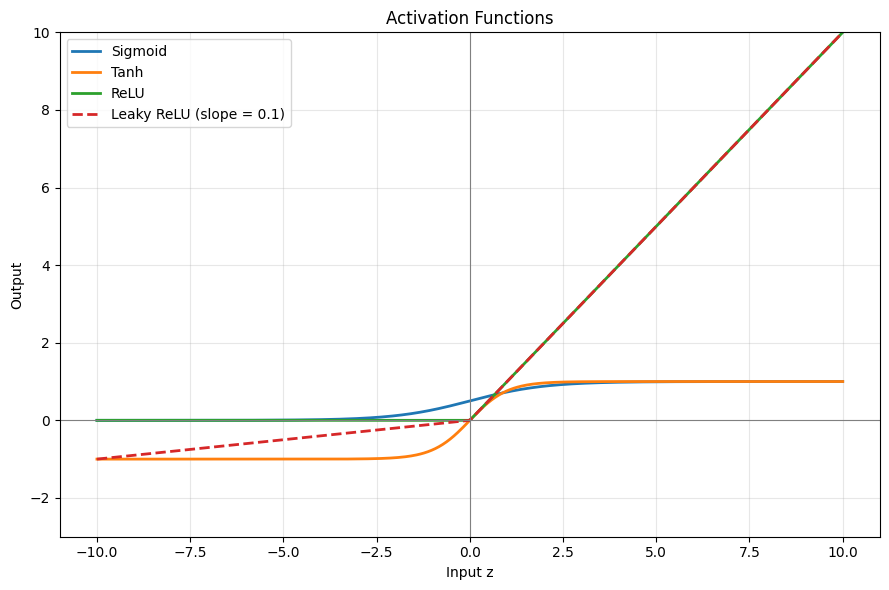

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a vector of inputs from -10 to 10
x = np.linspace(-10, 10, 400)

# 2. Activation functions
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def tanh(z):
    return np.tanh(z)

def relu(z):
    return np.maximum(0, z)

def leaky_relu(z, alpha=0.1):
    return np.where(z > 0, z, alpha * z)

y_sigmoid = sigmoid(x)
y_tanh = tanh(x)
y_relu = relu(x)
y_leaky = leaky_relu(x, alpha=0.1)

# 3. Plot all four on the same graph
plt.figure(figsize=(9, 6))
plt.plot(x, y_sigmoid, label="Sigmoid", linewidth=2)
plt.plot(x, y_tanh, label="Tanh", linewidth=2)
plt.plot(x, y_relu, label="ReLU", linewidth=2)
plt.plot(x, y_leaky, label="Leaky ReLU (slope = 0.1)", linewidth=2, linestyle="--")

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.title("Activation Functions")
plt.xlabel("Input z")
plt.ylabel("Output")
plt.ylim(-3, 10)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("activation_functions.png", dpi=150)
plt.show()

# 4. How the shape of each function affects learning
# Sigmoid: outputs in (0, 1) and is not zero-centered. For large |z| the curve
#   flattens, so the gradient is close to 0 (vanishing gradients). Its maximum
#   derivative is only 0.25, so gradients shrink layer by layer in deep networks
#   and learning becomes slow. Not zero-centered outputs also make updates zig-zag.
# Tanh: outputs in (-1, 1) and is zero-centered, which usually trains better than
#   sigmoid. It still saturates for large |z|, so its gradient also vanishes
#   (maximum derivative is 1, but it goes to 0 in the flat regions).
# ReLU: max(0, z). Gradient is 1 for z > 0 (no saturation, fast learning, cheap to
#   compute) and 0 for z < 0, so many neurons output exactly 0 (sparse activation).
#   Downside: "dying ReLU": a neuron stuck in the negative region gets zero
#   gradient and stops learning.
# Leaky ReLU: like ReLU but with a small slope (0.1) for z < 0, so the gradient is
#   never exactly 0. This avoids dying neurons while keeping ReLU's benefits, at
#   the cost of losing strict sparsity.